# Notebook 06 — Master Table Aggregation (schema-aware)

**Goal:** consolidate every per-model JSON (written by `run_full_audit` during notebooks 02-05) into the canonical `master.csv` (long format) and `master_wide.csv` (wide format) that all downstream analysis (notebooks 07-15) reads from. These two CSVs are the single source of truth for the paper.

**Why this notebook exists separately:** the per-model JSONs are append-only — notebooks 02 (params), 03 (FLOPs), 04 (memory), 05 (tokens) each merge their metric into the same `outputs/measurements/<sanitized_hf_id>.json`. Without an aggregator, every downstream notebook would have to re-walk the JSON tree. This notebook does that once and writes flat tables.

**v3 changes vs the old terse version (2026-05-22):**
* Schema-aware aggregation (`safe_sum` over `EXTENDED_COMPONENT_NAMES`) so Chameleon's `fused_transformer` and Janus-Pro's `vision_und`/`vision_gen` show up — no more silently-empty rows.
* Loads each of the nb02–nb05 summary CSVs and left-joins them onto the model identity (graceful skip if any CSV is missing).
* Adds a per-model **sanity column** that compares the sum of component params against the model's reported `fits_in_gb_fp16` ceiling, flagging deltas > 5%.
* Adds a coverage matrix + heatmap so you can see at a glance which (model × metric) pairs still need their notebook re-run.
* Three figures embedded for QA: param-share heatmap (model × component), coverage heatmap, family × schema clustermap.

**Inputs:**
* `../outputs/measurements/<sanitized_hf_id>.json` — one per model, populated by notebooks 02-05.
* `../outputs/measurements/nb02_parameter_summary.csv` — optional, joined for cross-check.
* `../outputs/measurements/nb03_flops_summary.csv` — optional.
* `../outputs/measurements/nb04_memory_summary.csv` — optional.
* `../outputs/measurements/nb05_token_summary.csv` — optional.

**Outputs:**
* `../outputs/measurements/master.csv` — long format, one row per (model, component). Used by notebooks 07, 08, 09 and any paper-table extraction.
* `../outputs/measurements/master_wide.csv` — wide format, one row per model with `<component>__<metric>` columns. Used by notebooks 07-09 for fast access.
* `../outputs/measurements/master_extended.csv` — wide-format slice for models with native-schema components only (currently Chameleon + Janus-Pro).
* `../outputs/measurements/nb06_coverage.csv` — which (model × metric) cells are populated.
* `../outputs/figures/nb06_param_share_heatmap.png` — model × component, color = share of total.
* `../outputs/figures/nb06_coverage_heatmap.png` — visual coverage matrix.
* `../outputs/figures/nb06_family_schema_grid.png` — family-by-schema model count grid.

**Compute:** CPU only. **Runtime:** under one minute.

**How to read this notebook:** run top-to-bottom. If a CSV is missing the corresponding section will warn and continue (no crash). At the end the §11 summary tells you which downstream notebooks are unblocked.

---
## 1. Setup (Runpod)

Pure CPU work — no GPU or HF_TOKEN required. The only dependencies are pandas, numpy and matplotlib. We still run the requirements install so the notebook is portable across hosts.

In [ ]:
# %%capture
# !pip install -q -r ../requirements.txt

In [1]:
import os, sys, json
from pathlib import Path
from collections import defaultdict

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from vlm_audit import MODELS
from vlm_audit.schema import ModelRecord
from vlm_audit.logging_utils import sanitize_for_filename
from vlm_audit.components import COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES

print(f'Working dir:        {NB_DIR}')
print(f'code_active dir:    {CODE_ACTIVE}')
print(f'measurements dir:   {MEASUREMENT_DIR}')
print(f'figures dir:        {FIG_DIR}')
print(f'Models in roster:   {len(MODELS)}')
print(f'JSONs on disk now:  {len(list(MEASUREMENT_DIR.glob("*.json")))}')
print(f'COMPONENT_NAMES:    {COMPONENT_NAMES}')
print(f'EXTENDED_NAMES:     {EXTENDED_COMPONENT_NAMES}')

Working dir:        /workspace/code_active/notebooks
code_active dir:    /workspace/code_active
measurements dir:   /workspace/code_active/outputs/measurements
figures dir:        /workspace/code_active/outputs/figures
Models in roster:   20
JSONs on disk now:  20
COMPONENT_NAMES:    ('vision', 'fusion', 'language', 'head')
EXTENDED_NAMES:     ('vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings')


---
## 2. Schema helpers (copied from notebook 02 v3)

Reused verbatim so this notebook is fully self-contained. Three schemas:

| Schema | Models | Notes |
|---|---|---|
| `standard_vflh` | 18 of 20 | V/F/L/H are populated; extended columns are 0 / absent. |
| `native_fused` | Chameleon-7B | V/F/L are `None`; `fused_transformer` carries the ~7B mass. |
| `decoupled_vision` | Janus-Pro-7B | Two vision pathways (`vision_und` + `vision_gen`); `vision` is an alias. |

`safe_sum()` sums any column suffix across the parts list, defaulting missing columns to 0 — so the same call works on every row regardless of schema.

In [2]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

EXTENDED_PARTS = list(EXTENDED_COMPONENT_NAMES)
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '__params_total') -> pd.Series:
    """Sum of parts[i]+suffix columns that exist in df. Missing cols treated as 0."""
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

assert schema_for('native_early_fusion') == 'native_fused'
assert schema_for('native_decoupled_encoder') == 'decoupled_vision'
assert schema_for('adapter_llm') == 'standard_vflh'
print('schema_for() OK')
print('safe_sum() OK')
print(f'EXTENDED_PARTS      = {EXTENDED_PARTS}')
print(f'VISION_LIKE_PARTS   = {VISION_LIKE_PARTS}')
print(f'LANGUAGE_LIKE_PARTS = {LANGUAGE_LIKE_PARTS}')

schema_for() OK
safe_sum() OK
EXTENDED_PARTS      = ['vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings']
VISION_LIKE_PARTS   = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']


---
## 3. Load every per-model JSON

Iterate the canonical `MODELS` roster and load each one's JSON via `ModelRecord.from_dict`. The `from_dict` is backwards-compatible with Phase-1 JSONs that lack the Phase-2 fields. Models with no JSON yet are logged into `missing`.

Each `ModelRecord` carries a `components` dict whose keys depend on schema (V/F/L/H for 18 models, V/F/L/H plus `fused_transformer`/`embeddings` for Chameleon, V/F/L/H plus `vision_und`/`vision_gen` for Janus-Pro). We unwind everything to a long-format DataFrame: one row per (model, component).

In [3]:
records = []          # list of (spec, rec) pairs
missing = []          # spec.name list with no JSON
load_errors = []      # (spec.name, exception) for unparseable JSONs

for spec in MODELS:
    path = MEASUREMENT_DIR / f'{sanitize_for_filename(spec.hf_id)}.json'
    if not path.exists():
        missing.append(spec.name)
        continue
    try:
        with open(path, 'r', encoding='utf-8') as f:
            rec = ModelRecord.from_dict(json.load(f))
        records.append((spec, rec))
    except Exception as e:
        load_errors.append((spec.name, f'{type(e).__name__}: {e}'))

print(f'Loaded:         {len(records):>3d} records')
print(f'Missing JSONs:  {len(missing):>3d}')
if missing:
    print('  ' + ', '.join(missing))
print(f'Load errors:    {len(load_errors):>3d}')
for name, err in load_errors:
    print(f'  {name}: {err}')

if not records:
    raise RuntimeError('No per-model JSONs found — run notebooks 02-05 first, then re-run this cell.')

Loaded:          20 records
Missing JSONs:    0
Load errors:      0


In [4]:
# Build the long-format DataFrame: one row per (model, component).
# Per-component metrics are pulled from the ComponentRecord dataclass.
long_rows = []
for spec, rec in records:
    sch = schema_for(spec.family)
    for cname, c in rec.components.items():
        long_rows.append({
            'model_id':              rec.model_id,
            'name':                  rec.name or spec.name,
            'family':                rec.family or spec.family,
            'schema':                sch,
            'release_year':          rec.release_year or spec.release_year,
            'architecture_pattern':  rec.architecture_pattern or spec.architecture_pattern,
            'component':             cname,
            'params_total':          c.params_total,
            'params_trainable':      c.params_trainable,
            'params_active':         c.params_active,
            'flops_g':               c.flops_g,
            'flops_source':          c.flops_source,
            'flops_estimate':        bool(c.flops_estimate) if c.flops_estimate is not None else False,
            'peak_mem_mb':           c.peak_mem_mb,
            'output_tokens':         c.output_tokens,
            'output_tokens_at_native_res': c.output_tokens_at_native_res,
            'output_tokens_at_224':  c.output_tokens_at_224,
            'module_path':           c.module_path,
            'notes':                 c.notes,
        })
long_df = pd.DataFrame(long_rows)
print(f'Long-format rows: {len(long_df)} (= {long_df["name"].nunique()} models × variable components)')
print(f'Components present in data: {sorted(long_df["component"].unique())}')
long_df.head(12)

Long-format rows: 84 (= 20 models × variable components)
Components present in data: ['embeddings', 'fused_transformer', 'fusion', 'head', 'language', 'vision', 'vision_gen', 'vision_und']


,model_id,name,family,schema,release_year,architecture_pattern,component,params_total,params_trainable,params_active,flops_g,flops_source,flops_estimate,peak_mem_mb,output_tokens,output_tokens_at_native_res,output_tokens_at_224,module_path,notes
0,openai/clip-vit-large-patch14,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,dual_tower_contrastive,fusion,1376256,1376256,NaN,NaN,,False,NaN,NaN,NaN,NaN,,
1,openai/clip-vit-large-patch14,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,dual_tower_contrastive,vision,303179776,303179776,NaN,155.660046,fvcore,False,596.070801,NaN,NaN,NaN,,
2,openai/clip-vit-large-patch14,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,dual_tower_contrastive,head,0,0,NaN,NaN,,False,NaN,NaN,NaN,NaN,,absent
3,openai/clip-vit-large-patch14,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,dual_tower_contrastive,language,123060480,123060480,NaN,10.877800,calflops,False,831.568848,1.0,NaN,NaN,,
4,google/siglip-large-patch16-384,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,dual_tower_contrastive,head,0,0,NaN,NaN,,False,NaN,NaN,NaN,NaN,,absent
5,google/siglip-large-patch16-384,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,dual_tower_contrastive,language,336194560,336194560,NaN,58.015600,calflops,False,1254.263672,1.0,NaN,NaN,,
6,google/siglip-large-patch16-384,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,dual_tower_contrastive,vision,316283904,316283904,NaN,119.322249,fvcore,False,617.596191,NaN,NaN,NaN,,
7,google/siglip-large-patch16-384,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,dual_tower_contrastive,fusion,0,0,NaN,NaN,,False,NaN,NaN,NaN,NaN,,absent
8,Salesforce/blip-image-captioning-large,BLIP-large,bridge_module_precursor,standard_vflh,2022,dense_adapter,vision,303690752,303690752,NaN,123.206234,fvcore,False,595.582031,NaN,NaN,NaN,,
9,Salesforce/blip-image-captioning-large,BLIP-large,bridge_module_precursor,standard_vflh,2022,dense_adapter,head,0,0,NaN,NaN,,False,NaN,NaN,NaN,NaN,,absent


---
## 4. Load supplementary CSVs from notebooks 02-05

Each upstream notebook persists its own summary CSV. These are richer than what the per-model JSONs encode (the JSONs are deliberately minimal). If any of these CSVs is missing we **skip that join silently** so the aggregator never crashes — only the affected columns will be absent in `master_wide.csv`.

| CSV | Source | Joined onto |
|---|---|---|
| `nb02_parameter_summary.csv` | notebook 02 | `name` |
| `nb03_flops_summary.csv` | notebook 03 | `name` |
| `nb04_memory_summary.csv` | notebook 04 | `name` |
| `nb05_token_summary.csv` | notebook 05 | `name` |

In [5]:
SUPP_CSVS = {
    'nb02_parameter_summary.csv': 'nb02',
    'nb03_flops_summary.csv':     'nb03',
    'nb04_memory_summary.csv':    'nb04',
    'nb05_token_summary.csv':     'nb05',
}
supp_loaded = {}
for fname, tag in SUPP_CSVS.items():
    p = MEASUREMENT_DIR / fname
    if not p.exists():
        print(f'  ⚠ {fname:35s} MISSING — corresponding columns will be skipped')
        continue
    try:
        sd = pd.read_csv(p)
    except Exception as e:
        print(f'  ✗ {fname:35s} unreadable: {e}')
        continue
    print(f'  ✓ {fname:35s} {len(sd):>3d} rows, {len(sd.columns):>3d} cols')
    supp_loaded[tag] = sd
print(f'\nLoaded {len(supp_loaded)} of {len(SUPP_CSVS)} supplementary CSVs')

  ✓ nb02_parameter_summary.csv           20 rows,  39 cols
  ✓ nb03_flops_summary.csv               20 rows,  45 cols
  ✓ nb04_memory_summary.csv              20 rows,  30 cols
  ✓ nb05_token_summary.csv               20 rows,  13 cols

Loaded 4 of 4 supplementary CSVs


---
## 5. Build `master.csv` (long format)

The long-format CSV is the canonical export. One row per (model, component). Notebooks 07 and 08 read this when they want per-component slicing. Save it now (we'll keep the in-memory `long_df` for the rest of this notebook).

In [6]:
master_csv = MEASUREMENT_DIR / 'master.csv'
long_df.to_csv(master_csv, index=False)
print(f'Wrote: {master_csv}')
print(f'  Rows:    {len(long_df)}')
print(f'  Models:  {long_df["name"].nunique()}')
print(f'  Schemas: {long_df.groupby("schema")["name"].nunique().to_dict()}')
print(f'  Columns: {list(long_df.columns)}')

Wrote: /workspace/code_active/outputs/measurements/master.csv
  Rows:    84
  Models:  20
  Schemas: {'decoupled_vision': 1, 'native_fused': 1, 'standard_vflh': 18}
  Columns: ['model_id', 'name', 'family', 'schema', 'release_year', 'architecture_pattern', 'component', 'params_total', 'params_trainable', 'params_active', 'flops_g', 'flops_source', 'flops_estimate', 'peak_mem_mb', 'output_tokens', 'output_tokens_at_native_res', 'output_tokens_at_224', 'module_path', 'notes']


---
## 6. Build `master_wide.csv` (wide format) — schema-aware

One row per model with `<component>__<metric>` columns. Standard V/F/L/H columns are always present (set to NaN for rows where the schema doesn't have that component). Extended columns (`fused_transformer__*`, `vision_und__*`, `vision_gen__*`, `embeddings__*`) are written when the component exists in *any* row, even if most rows are NaN — that's how downstream notebooks know they can opt in to native-schema metrics.

Metrics included per component: `params_total`, `params_trainable`, `params_active`, `flops_g`, `peak_mem_mb`, `output_tokens`, `output_tokens_at_native_res`, `output_tokens_at_224`.

In [7]:
WIDE_METRICS = [
    'params_total', 'params_trainable', 'params_active',
    'flops_g', 'peak_mem_mb',
    'output_tokens', 'output_tokens_at_native_res', 'output_tokens_at_224',
]
WIDE_IDENTITY = ['model_id', 'name', 'family', 'schema', 'release_year', 'architecture_pattern']

# Pivot long → wide. Use multi-index column construction so missing schemas come through as NaN.
wide_rows = []
for spec, rec in records:
    sch = schema_for(spec.family)
    row = {
        'model_id':             rec.model_id,
        'name':                 rec.name or spec.name,
        'family':               rec.family or spec.family,
        'schema':               sch,
        'release_year':         rec.release_year or spec.release_year,
        'architecture_pattern': rec.architecture_pattern or spec.architecture_pattern,
    }
    for part in EXTENDED_PARTS:
        c = rec.components.get(part)
        for m in WIDE_METRICS:
            row[f'{part}__{m}'] = getattr(c, m, None) if c is not None else None
    wide_rows.append(row)

wide_df = pd.DataFrame(wide_rows)
# Reorder columns: identity first, then each part's metrics grouped together (so master_wide.csv
# is human-readable in Excel).
ordered = list(WIDE_IDENTITY)
for part in EXTENDED_PARTS:
    ordered += [f'{part}__{m}' for m in WIDE_METRICS]
wide_df = wide_df[ordered]

master_wide_csv = MEASUREMENT_DIR / 'master_wide.csv'
wide_df.to_csv(master_wide_csv, index=False)
print(f'Wrote: {master_wide_csv}')
print(f'  Rows: {len(wide_df)}  Cols: {len(wide_df.columns)}')
wide_df[['name', 'family', 'schema', 'vision__params_total', 'fusion__params_total',
         'language__params_total', 'head__params_total',
         'fused_transformer__params_total', 'vision_und__params_total', 'vision_gen__params_total']].sort_values(['schema', 'family']).reset_index(drop=True)

Wrote: /workspace/code_active/outputs/measurements/master_wide.csv
  Rows: 20  Cols: 70


,name,family,schema,vision__params_total,fusion__params_total,language__params_total,head__params_total,fused_transformer__params_total,vision_und__params_total,vision_gen__params_total
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,316283904,20979712,6910365696,0,NaN,316283904.0,71948939.0
1,Chameleon-7B,native_early_fusion,native_fused,0,0,0,268435456,6.774655e+09,NaN,NaN
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,303507456,20979712,6607605760,131334144,NaN,NaN,NaN
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,303507456,20979712,7110922240,131334144,NaN,NaN,NaN
4,Molmo-7B-D,adapter_llm,standard_vflh,404950016,0,7616075264,0,NaN,NaN,NaN
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,403489792,31467520,11576693760,671088640,NaN,NaN,NaN
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,985952256,105137664,2651678720,1968640,NaN,NaN,NaN
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,985952256,185660160,6738939904,3149824,NaN,NaN,NaN
8,BLIP-large,bridge_module_precursor,standard_vflh,303690752,0,142599740,0,NaN,NaN,NaN
9,IDEFICS-9B,cross_attention_llm,standard_vflh,630766080,125961984,6607351808,131080192,NaN,NaN,NaN


In [8]:
# Extended-only slice: keep rows whose schema is NOT standard_vflh.
ext_df = wide_df[wide_df['schema'].isin(['native_fused', 'decoupled_vision'])].copy()
ext_csv = MEASUREMENT_DIR / 'master_extended.csv'
if len(ext_df) > 0:
    ext_df.to_csv(ext_csv, index=False)
    print(f'Wrote: {ext_csv}  ({len(ext_df)} native-schema rows)')
    print('Models in extended slice:', list(ext_df["name"]))
else:
    print('No native-schema models in current data — skipping master_extended.csv')
ext_df if len(ext_df) > 0 else None

Wrote: /workspace/code_active/outputs/measurements/master_extended.csv  (2 native-schema rows)
Models in extended slice: ['Chameleon-7B', 'Janus-Pro-7B']


,model_id,name,family,schema,release_year,architecture_pattern,vision__params_total,vision__params_trainable,vision__params_active,vision__flops_g,...,vision_gen__output_tokens_at_native_res,vision_gen__output_tokens_at_224,embeddings__params_total,embeddings__params_trainable,embeddings__params_active,embeddings__flops_g,embeddings__peak_mem_mb,embeddings__output_tokens,embeddings__output_tokens_at_native_res,embeddings__output_tokens_at_224
18,facebook/chameleon-7b,Chameleon-7B,native_early_fusion,native_fused,2024,early_fusion,0,0,None,NaN,...,None,None,268435456.0,268435456.0,None,None,None,None,None,None
19,deepseek-ai/Janus-Pro-7B,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,2025,decoupled_encoder,316283904,316283904,None,461.141932,...,None,None,NaN,NaN,None,None,None,None,None,None


---
## 7. Sanity table — sum vs. fp16 footprint ceiling

For each model compute the sum of `params_total` across components (schema-aware via `safe_sum`) and compare against the spec's `fits_in_gb_fp16` declaration in `models.py`. A bf16/fp16 weight is 2 bytes, so `total_params * 2 / 1e9` should be roughly `fits_in_gb_fp16` (it's a lower bound — `fits_in_gb_fp16` includes some activation headroom).

Flag rows where the **measured** weight footprint exceeds the declared ceiling by > 5% (would indicate `models.py` is stale) or where the measured footprint is < 50% of the ceiling (could indicate a missed component — extractor bug).

In [9]:
wide_df['_total_params_schema_aware']    = safe_sum(wide_df, EXTENDED_PARTS, '__params_total')
wide_df['_total_params_M']               = (wide_df['_total_params_schema_aware'] / 1e6).round(2)
wide_df['_measured_fp16_GB']             = (wide_df['_total_params_schema_aware'] * 2 / 1e9).round(3)

# Look up declared fp16 ceiling from MODELS roster
declared = {m.name: m.fits_in_gb_fp16 for m in MODELS}
wide_df['_declared_fp16_GB']             = wide_df['name'].map(declared)
wide_df['_delta_pct_vs_declared']        = (100 * (wide_df['_measured_fp16_GB'] - wide_df['_declared_fp16_GB']) / wide_df['_declared_fp16_GB'].replace(0, np.nan)).round(1)

def _flag(row):
    d = row['_delta_pct_vs_declared']
    if pd.isna(d):
        return 'no declaration'
    if d > 5:
        return f'⚠ over by {d:.1f}%'
    if d < -50:
        return f'⚠ under by {abs(d):.1f}% — extractor may be missing a component'
    return '✓ within tolerance'

wide_df['_sanity_flag'] = wide_df.apply(_flag, axis=1)
sanity_view = wide_df[['name', 'family', 'schema', '_total_params_M', '_measured_fp16_GB',
                       '_declared_fp16_GB', '_delta_pct_vs_declared', '_sanity_flag']].sort_values('_delta_pct_vs_declared')
sanity_view.reset_index(drop=True)

,name,family,schema,_total_params_M,_measured_fp16_GB,_declared_fp16_GB,_delta_pct_vs_declared,_sanity_flag
0,ViLT-B/32,single_stream_fused,standard_vflh,117.00,0.234,0.5,-53.2,⚠ under by 53.2% — extractor may be missing a ...
1,IDEFICS-9B,cross_attention_llm,standard_vflh,7495.16,14.990,18.0,-16.7,✓ within tolerance
2,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,427.62,0.855,1.0,-14.5,✓ within tolerance
3,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,652.48,1.305,1.5,-13.0,✓ within tolerance
4,LLaVA-1.5-7B,adapter_llm,standard_vflh,7063.43,14.127,16.0,-11.7,✓ within tolerance
5,BLIP-large,bridge_module_precursor,standard_vflh,446.29,0.893,1.0,-10.7,✓ within tolerance
6,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,7913.70,15.827,17.0,-6.9,✓ within tolerance
7,LLaVA-NeXT-7B,adapter_llm,standard_vflh,7566.74,15.133,16.0,-5.4,✓ within tolerance
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,standard_vflh,10670.22,21.340,22.0,-3.0,✓ within tolerance
9,Qwen2.5-VL-7B-Instruct,dynamic_tile_adapter_llm,standard_vflh,8336.74,16.673,17.0,-1.9,✓ within tolerance


In [10]:
# Print just the problem rows so they don't get lost in the table.
problems = sanity_view[~sanity_view['_sanity_flag'].str.startswith('✓')]
if problems.empty:
    print('✓ All models within ±5% (over) / ±50% (under) of declared fp16 footprint.')
else:
    print(f'⚠ {len(problems)} sanity flags raised:')
    for _, r in problems.iterrows():
        print(f'  - {r["name"]:30s} measured {r["_measured_fp16_GB"]:.2f} GB · declared {r["_declared_fp16_GB"]:.2f} GB · {r["_sanity_flag"]}')
    print('\nInterpretation:')
    print('  "over by N%" usually means models.py declares too small a number — update fits_in_gb_fp16.')
    print('  "under by N%" usually means the extractor for that family is missing a component — investigate components.py.')

⚠ 6 sanity flags raised:
  - ViLT-B/32                      measured 0.23 GB · declared 0.50 GB · ⚠ under by 53.2% — extractor may be missing a component
  - Pixtral-12B                    measured 25.36 GB · declared 24.00 GB · ⚠ over by 5.7%
  - BLIP-2-OPT-2.7B                measured 7.49 GB · declared 7.00 GB · ⚠ over by 7.0%
  - DeepSeek-VL2-Small             measured 32.30 GB · declared 30.00 GB · ⚠ over by 7.7%
  - Janus-Pro-7B                   measured 15.27 GB · declared 14.00 GB · ⚠ over by 9.1%
  - SigLIP2-So400m/14              measured 2.27 GB · declared 1.50 GB · ⚠ over by 51.5%

Interpretation:
  "over by N%" usually means models.py declares too small a number — update fits_in_gb_fp16.
  "under by N%" usually means the extractor for that family is missing a component — investigate components.py.


---
## 8. Coverage matrix — which (model × metric) cells are populated?

A green check means at least one component of that model has a non-null value for the metric; a red cross means every component is null. Quick way to spot "I need to re-run notebook 04 on these 3 models".

The four metrics tracked are params, FLOPs, memory, output tokens. We deliberately exclude `params_active` (MoE-only) and `output_tokens_at_*` (dynamic-tile only) from the coverage matrix — those aren't expected to be populated for every model.

In [11]:
METRICS_FOR_COVERAGE = ['params_total', 'flops_g', 'peak_mem_mb', 'output_tokens']
coverage_rows = []
for spec, rec in records:
    sch = schema_for(spec.family)
    row = {'name': spec.name, 'family': spec.family, 'schema': sch}
    for m in METRICS_FOR_COVERAGE:
        has = False
        for c in rec.components.values():
            v = getattr(c, m, None)
            if v is not None and v != 0:
                has = True
                break
        # params_total is special — 0 means "this component genuinely has no params" (CLIP head)
        # but we want the model to count as covered if any of its components has > 0 params.
        if m == 'params_total':
            has = any((c.params_total or 0) > 0 for c in rec.components.values())
        row[m] = has
    coverage_rows.append(row)

coverage_df = pd.DataFrame(coverage_rows)
coverage_csv = MEASUREMENT_DIR / 'nb06_coverage.csv'
coverage_df.to_csv(coverage_csv, index=False)

# Pretty-print
pretty = coverage_df.copy()
for m in METRICS_FOR_COVERAGE:
    pretty[m] = pretty[m].map({True: '✓', False: '✗'})
print(f'Coverage by metric:')
for m in METRICS_FOR_COVERAGE:
    n_ok = int(coverage_df[m].sum())
    print(f'  {m:18s} {n_ok:>2d}/{len(coverage_df)} models populated')
pretty.sort_values(['family', 'name']).reset_index(drop=True)

Coverage by metric:
  params_total       20/20 models populated
  flops_g            20/20 models populated
  peak_mem_mb        18/20 models populated
  output_tokens      19/20 models populated


,name,family,schema,params_total,flops_g,peak_mem_mb,output_tokens
0,LLaVA-1.5-7B,adapter_llm,standard_vflh,✓,✓,✓,✓
1,LLaVA-NeXT-7B,adapter_llm,standard_vflh,✓,✓,✓,✓
2,Molmo-7B-D,adapter_llm,standard_vflh,✓,✓,✗,✓
3,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,✓,✓,✓,✓
4,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,✓,✓,✓,✓
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,✓,✓,✓,✓
6,BLIP-large,bridge_module_precursor,standard_vflh,✓,✓,✓,✓
7,IDEFICS-9B,cross_attention_llm,standard_vflh,✓,✓,✓,✓
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,standard_vflh,✓,✓,✓,✓
9,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,✓,✓,✓,✓


---
## 9. Figures

Three diagnostic figures for QA:

1. **Param-share heatmap** (model rows × extended-component columns) — color = share of that model's total. Makes it visually obvious that CLIP rows are vision-dominant, LLaVA rows are language-dominant, Chameleon rows are entirely `fused_transformer`-dominant.
2. **Coverage heatmap** (model rows × {params, FLOPs, memory, tokens}) — same data as §8 but visually.
3. **Family × schema model count grid** — sanity check that each family's expected schema is represented.

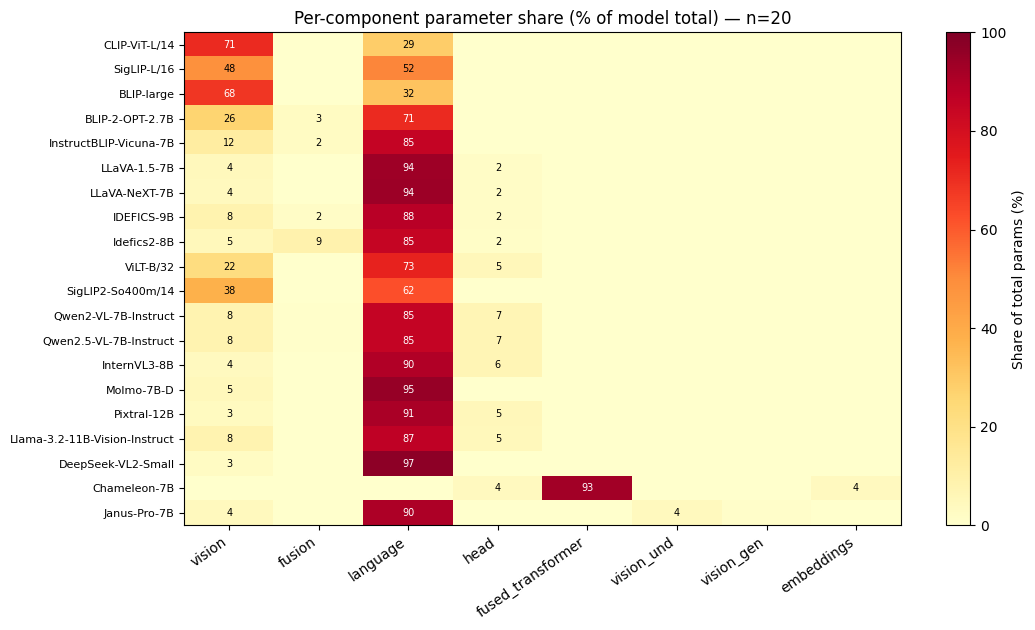

Saved /workspace/code_active/outputs/figures/nb06_param_share_heatmap.png


In [12]:
# Figure 1: param share heatmap.
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap

heat_parts = list(EXTENDED_PARTS)  # all 8 extended slots
heat_data = []
for spec, rec in records:
    total = sum((c.params_total or 0) for c in rec.components.values())
    if total == 0:
        heat_data.append([np.nan] * len(heat_parts))
        continue
    row = []
    for part in heat_parts:
        c = rec.components.get(part)
        v = (c.params_total if c else 0) or 0
        row.append(100 * v / total)
    heat_data.append(row)

heat_arr = np.array(heat_data)
labels = [s.name for s, _ in records]

fig, ax = plt.subplots(figsize=(11, max(6, 0.32 * len(labels))))
im = ax.imshow(heat_arr, aspect='auto', cmap='YlOrRd', vmin=0, vmax=100)
ax.set_xticks(np.arange(len(heat_parts)))
ax.set_xticklabels(heat_parts, rotation=35, ha='right')
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=8)
ax.set_title(f'Per-component parameter share (% of model total) — n={len(labels)}')
cbar = plt.colorbar(im, ax=ax, label='Share of total params (%)')
# Annotate each cell with its value (only if > 1% so the chart isn't cluttered)
for i in range(heat_arr.shape[0]):
    for j in range(heat_arr.shape[1]):
        v = heat_arr[i, j]
        if not np.isnan(v) and v >= 1:
            txt_color = 'white' if v > 60 else 'black'
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color=txt_color)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb06_param_share_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb06_param_share_heatmap.png"}')

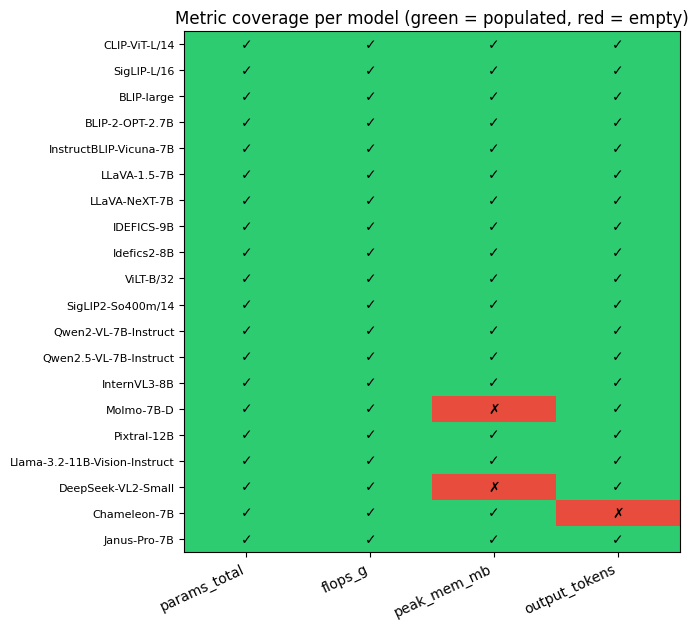

Saved /workspace/code_active/outputs/figures/nb06_coverage_heatmap.png


In [13]:
# Figure 2: coverage heatmap.
cov_arr = coverage_df[METRICS_FOR_COVERAGE].astype(int).values
fig, ax = plt.subplots(figsize=(7, max(5, 0.32 * len(coverage_df))))
cmap = LinearSegmentedColormap.from_list('rg', ['#E74C3C', '#2ECC71'])
im = ax.imshow(cov_arr, aspect='auto', cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(np.arange(len(METRICS_FOR_COVERAGE)))
ax.set_xticklabels(METRICS_FOR_COVERAGE, rotation=25, ha='right')
ax.set_yticks(np.arange(len(coverage_df)))
ax.set_yticklabels(coverage_df['name'], fontsize=8)
ax.set_title('Metric coverage per model (green = populated, red = empty)')
for i in range(cov_arr.shape[0]):
    for j in range(cov_arr.shape[1]):
        ax.text(j, i, '✓' if cov_arr[i, j] else '✗', ha='center', va='center', fontsize=10, color='black')
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb06_coverage_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb06_coverage_heatmap.png"}')

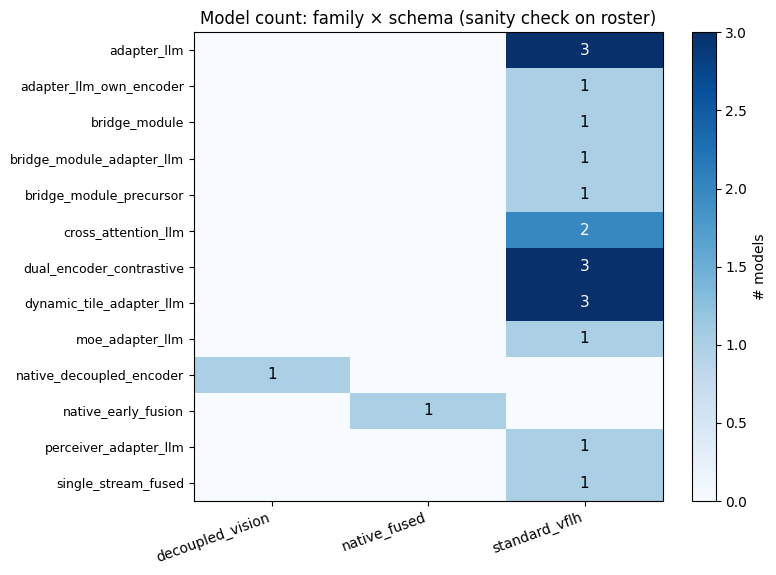

Saved /workspace/code_active/outputs/figures/nb06_family_schema_grid.png


schema,decoupled_vision,native_fused,standard_vflh
family,,,
adapter_llm,0,0,3
adapter_llm_own_encoder,0,0,1
bridge_module,0,0,1
bridge_module_adapter_llm,0,0,1
bridge_module_precursor,0,0,1
cross_attention_llm,0,0,2
dual_encoder_contrastive,0,0,3
dynamic_tile_adapter_llm,0,0,3
moe_adapter_llm,0,0,1


In [14]:
# Figure 3: family × schema model count grid.
grid = wide_df.groupby(['family', 'schema']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(8, max(4, 0.45 * len(grid))))
im = ax.imshow(grid.values, cmap='Blues', aspect='auto')
ax.set_xticks(np.arange(len(grid.columns)))
ax.set_xticklabels(grid.columns, rotation=20, ha='right')
ax.set_yticks(np.arange(len(grid.index)))
ax.set_yticklabels(grid.index, fontsize=9)
ax.set_title('Model count: family × schema (sanity check on roster)')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if v > 0:
            ax.text(j, i, str(v), ha='center', va='center', fontsize=11,
                    color='white' if v > grid.values.max()/2 else 'black')
plt.colorbar(im, ax=ax, label='# models')
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb06_family_schema_grid.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_DIR / "nb06_family_schema_grid.png"}')
grid

---
## 10. Cross-check against supplementary CSVs

If notebook 02 ran, the per-model parameter totals it produced should equal the ones we just derived from the JSONs (modulo the schema-aware aggregation). Same for FLOPs (nb03), memory (nb04), tokens (nb05). Any mismatch is worth investigating before downstream analysis.

In [15]:
# Cross-check vs nb02_parameter_summary.csv if present.
if 'nb02' in supp_loaded:
    nb02 = supp_loaded['nb02']
    if 'total_M' in nb02.columns and 'name' in nb02.columns:
        cross = wide_df.merge(nb02[['name', 'total_M']], on='name', how='left', suffixes=('', '_nb02'))
        cross['_delta_M'] = cross['_total_params_M'] - cross['total_M']
        cross['_delta_pct'] = (100 * cross['_delta_M'] / cross['total_M'].replace(0, np.nan)).round(2)
        problems = cross[cross['_delta_pct'].abs() > 0.5]
        if problems.empty:
            print(f'✓ nb02 param totals match master_wide for all {len(cross)} models (within 0.5%)')
        else:
            print(f'⚠ {len(problems)} models disagree by >0.5%:')
            print(problems[['name', 'total_M', '_total_params_M', '_delta_M', '_delta_pct']].to_string(index=False))
    else:
        print('nb02 csv present but does not have expected columns (name + total_M); skipping cross-check')
else:
    print('nb02 csv not loaded — skipping cross-check')

✓ nb02 param totals match master_wide for all 20 models (within 0.5%)


---
## 11. Outputs summary

Final inventory of what we wrote and where. Use this to confirm downstream notebooks are unblocked.

In [16]:
outputs = [
    ('master.csv',                MEASUREMENT_DIR / 'master.csv',                f'{len(long_df)} rows · long format'),
    ('master_wide.csv',           MEASUREMENT_DIR / 'master_wide.csv',           f'{len(wide_df)} rows · wide format'),
    ('master_extended.csv',       MEASUREMENT_DIR / 'master_extended.csv',       f'{len(ext_df)} rows · native-schema only'),
    ('nb06_coverage.csv',         MEASUREMENT_DIR / 'nb06_coverage.csv',         f'{len(coverage_df)} rows · coverage matrix'),
    ('nb06_param_share_heatmap.png', FIG_DIR / 'nb06_param_share_heatmap.png',  '300dpi'),
    ('nb06_coverage_heatmap.png', FIG_DIR / 'nb06_coverage_heatmap.png',         '300dpi'),
    ('nb06_family_schema_grid.png', FIG_DIR / 'nb06_family_schema_grid.png',    '300dpi'),
]
print(f'{"FILE":42s}  {"PATH":80s}  NOTES')
print('-' * 140)
for label, p, note in outputs:
    status = '✓' if p.exists() else '✗'
    print(f'{status} {label:40s}  {str(p):80s}  {note}')

FILE                                        PATH                                                                              NOTES
--------------------------------------------------------------------------------------------------------------------------------------------
✓ master.csv                                /workspace/code_active/outputs/measurements/master.csv                            84 rows · long format
✓ master_wide.csv                           /workspace/code_active/outputs/measurements/master_wide.csv                       20 rows · wide format
✓ master_extended.csv                       /workspace/code_active/outputs/measurements/master_extended.csv                   2 rows · native-schema only
✓ nb06_coverage.csv                         /workspace/code_active/outputs/measurements/nb06_coverage.csv                     20 rows · coverage matrix
✓ nb06_param_share_heatmap.png              /workspace/code_active/outputs/figures/nb06_param_share_heatmap.png              

---
## Next steps

* Open **`07_within_family_consistency.ipynb`** — reads `master_wide.csv`, verifies that families with multiple representatives produce internally consistent measurements.
* Open **`08_findings_F1_to_F10.ipynb`** — the headline analysis notebook; builds the F1–F10 evidence tables that map directly to claims in the paper.
* Open **`09_figures_09_10_11.ipynb`** — produces the publication-quality fig 09/10/11 used in the paper.

If the sanity table (§7) raised flags, fix `vlm_audit/models.py` (declared GB) or `vlm_audit/components.py` (extractor) and re-run notebooks 02-05 for the affected models before continuing.

*End of notebook 06 (v3 — 2026-05-22).*